# Laboratorio 3 - La tarea de clasificación

*Presentado por:*
- Shaiel Jiménez - 202323846
- Juan Esteban Triviño - 202315338

*ISIS2611 - Aprendizaje de Máquina / Sección 5*

*Profesor: Rubén Manrique*

**Contenido**

1. [Introducción](#introduccion)
2. [Configuración del entorno](#entorno)
3. [Actividad 1 - Exploración de los datos](#actividad1)
4. [Actividad 2 - Limpieza y preparación](#actividad2)
5. [Actividad 3 - Regresión logística](#actividad3)
6. [Actividad 4 - Árboles de decisión](#actividad4)
7. [Actividad 5 - Random Forest](#actividad5)
8. [Actividad 6 - Balanceo de clases (Restaurante(<20))](#actividad6)
9. [Actividad 7 - Tabla comparativa](#actividad7)
10. [Actividad 8 - Variables más relevantes](#actividad8)
11. [Actividad 10 - Predicciones sobre los datos de prueba](#actividad10)
12. [Análisis de resultados](#analisis)
13. [Uso de herramientas de IA generativa](#iag)

## <a id="introduccion"></a> Introducción

*(Por completar: contexto del caso Ruta Alpes, objetivo, resumen de decisiones metodológicas.)*

## <a id="entorno"></a> Configuración del entorno

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score,
)

# SMOTE y Pipeline de imblearn (Actividad 6)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
DATA_DIR = Path("data/raw")
RUTA_DATOS = DATA_DIR / "Lab3_Datos.xlsx"
RUTA_PRUEBA = DATA_DIR / "Lab3_datos_Prueba.xlsx"
RUTA_DICCIONARIO = DATA_DIR / "Lab3_diccionario_Datos.xlsx"

# Mismos folds para todos los modelos
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Archivos de datos:", [p.name for p in DATA_DIR.glob("*.xlsx")])

Archivos de datos: ['Lab3_Datos.xlsx', 'Lab3_diccionario_Datos.xlsx', 'Lab3_datos_Prueba.xlsx']


## <a id="actividad1"></a> Actividad 1 - Exploración de los datos

### 1.1 Carga y estructura

Se cargan los datos de entrenamiento, los de prueba y el diccionario. Lo que se lee se guarda en `datos_originales` y `prueba_original`, y se trabaja siempre sobre las copias `df` y `prueba`, para no alterar los originales.

In [3]:
datos_originales = pd.read_excel(RUTA_DATOS)
prueba_original = pd.read_excel(RUTA_PRUEBA)
diccionario = pd.read_excel(RUTA_DICCIONARIO)

# Copias de trabajo: los originales no se modifican
df = datos_originales.copy()
prueba = prueba_original.copy()

print(f"Entrenamiento: {df.shape} | Prueba: {prueba.shape} | Diccionario: {diccionario.shape}")
pd.DataFrame({"tipo": df.dtypes, "valores_unicos": df.nunique()})

Entrenamiento: (12664, 26) | Prueba: (20, 25) | Diccionario: (26, 3)


,tipo,valores_unicos
destino,str,3
acompanante,str,4
clima,str,3
temperatura,int64,3
hora,str,5
cupon,str,5
vigencia_cupon,str,2
genero,str,2
edad,str,8
estado_civil,str,5


In [4]:
cols_dic = set(diccionario["Variable"])
print("Columnas del diccionario que faltan en los datos:", cols_dic - set(df.columns))
print("Columnas de los datos que no están en el diccionario:", set(df.columns) - cols_dic)
print("Diferencia entre entrenamiento y prueba:", set(df.columns) ^ set(prueba.columns))

Columnas del diccionario que faltan en los datos: set()
Columnas de los datos que no están en el diccionario: set()
Diferencia entre entrenamiento y prueba: {'acepta_cupon'}


**Hallazgos.** Los datos coinciden con el diccionario y el archivo de prueba solo se diferencia en `acepta_cupon`, que es lo que se quiere predecir. Solo `temperatura` es numérica; el resto son categóricas, y `edad` mezcla números con textos como "menor de 21" y "50 o más". `tiempo_cupon_mayor_5min` tiene un único valor.

### 1.2 Valores nulos

Se revisa cuántos faltantes hay, en qué columnas y si siguen algún patrón.

In [5]:
nulos = df.isna().sum()
tabla_nulos = pd.DataFrame({"nulos": nulos, "%": (nulos / len(df) * 100).round(2)})
tabla_nulos[tabla_nulos["nulos"] > 0]

,nulos,%
vehiculo,12556,99.15
frecuencia_bar,107,0.84
frecuencia_cafeteria,217,1.71
frecuencia_comida_para_llevar,151,1.19
frecuencia_restaurante_menos_20,130,1.03
frecuencia_restaurante_20_a_50,189,1.49


In [6]:
print("Nulos en el archivo de prueba:", prueba.isna().sum()[lambda s: s > 0].to_dict())

# Los nulos de frecuencia_* ¿son del conductor o del escenario?
perfil = ["genero", "edad", "estado_civil", "tiene_hijos", "educacion", "ocupacion", "ingreso"]
frec = [c for c in df.columns if c.startswith("frecuencia_")]
print(f"Perfiles distintos de conductor: {df[perfil].drop_duplicates().shape[0]} en {len(df)} filas")

por_perfil = df.assign(nulo=df[frec].isna().any(axis=1)).groupby(perfil)["nulo"].mean()
print(f"Perfiles con nulos en frecuencia_*: {(por_perfil > 0).sum()} | con nulos en todas sus filas: {(por_perfil == 1).sum()}")

Nulos en el archivo de prueba: {'vehiculo': 20}
Perfiles distintos de conductor: 519 en 12664 filas
Perfiles con nulos en frecuencia_*: 33 | con nulos en todas sus filas: 29


**Hallazgos y decisiones.** `vehiculo` está vacía en el 99% de las filas y siempre en la prueba, así que se elimina. Las `frecuencia_*` tienen entre 0.8% y 1.7% de nulos y casi siempre faltan en todas las filas de un mismo conductor, es decir, son preguntas que esa persona no contestó. Como son pocos, se imputan con la moda dentro del pipeline, para que se calcule solo con el entrenamiento y no haya fuga de datos; eliminar filas quitaría conductores completos.

Además, hay solo 519 perfiles de conductor en más de 12 mil filas, lo que significa que cada persona aparece en varios escenarios. Esto se revisa en 1.5.

### 1.3 Subconjuntos por tipo de cupón

El enunciado pide un modelo para Cafetería y otro para Restaurante(<20). Se modelan por separado porque lo que lleva a aceptar uno no tiene por qué llevar a aceptar el otro, y así se pueden comparar.

In [7]:
df["cupon"].value_counts().to_frame("filas")

,filas
cupon,
Cafetería,3986
Restaurante(<20),2776
Comida para llevar,2393
Bar,2017
Restaurante(20-50),1492


In [8]:
cafe = df[df["cupon"] == "Cafetería"].copy()
rest = df[df["cupon"] == "Restaurante(<20)"].copy()

print(f"Cafetería: {len(cafe)} | Restaurante(<20): {len(rest)} | Total: {len(cafe) + len(rest)} ({(len(cafe) + len(rest)) / len(df):.1%} del archivo)")
print("Cupones en la prueba:", prueba["cupon"].value_counts().to_dict())

Cafetería: 3986 | Restaurante(<20): 2776 | Total: 6762 (53.4% del archivo)
Cupones en la prueba: {'Cafetería': 10, 'Restaurante(<20)': 10}


**Hallazgos.** Los dos subconjuntos suman 6762 filas (53.4% del archivo); los demás cupones no se usan. En el archivo de prueba hay solo 10 filas de cada cupón, así que sirve para las predicciones finales pero no para elegir modelos. `cupon` es constante dentro de cada subconjunto y se elimina en la limpieza.

### 1.4 Distribución de la variable objetivo

Se mira cuántos aceptan y cuántos rechazan en cada cupón, porque de eso depende qué métricas usar.

In [9]:
dist = pd.concat({"Cafetería": cafe["acepta_cupon"], "Restaurante(<20)": rest["acepta_cupon"]}, names=["cupon"])
dist = dist.groupby("cupon").value_counts().to_frame("filas")
dist["%"] = (dist["filas"] / dist.groupby("cupon")["filas"].transform("sum") * 100).round(1)
dist

filas     %
cupon            acepta_cupon             
Cafetería        No             1997  50.1
                 Sí             1989  49.9
Restaurante(<20) Sí             1962  70.7
                 No              814  29.3

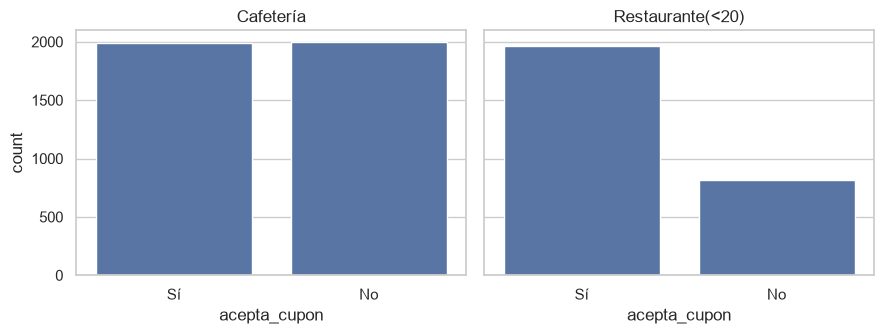

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for ax, (nombre, datos) in zip(axes, [("Cafetería", cafe), ("Restaurante(<20)", rest)]):
    sns.countplot(data=datos, x="acepta_cupon", order=["Sí", "No"], ax=ax)
    ax.set_title(nombre)
    ax.set_xlabel("acepta_cupon")
plt.tight_layout()
plt.show()

**Hallazgos.** En **Cafetería** las clases están parejas (49.9% acepta), mientras que en **Restaurante(<20)** acepta el 70.7% y rechaza el 29.3%, de modo que la clase minoritaria es el rechazo.

Con ese desbalance la exactitud engaña, ya que responder siempre "Sí" acertaría el 70.7% sin detectar ningún rechazo. Por eso se reportan precisión, recall y F1 por clase, y se usa el **F1 macro** (promedio del F1 de las dos clases) para elegir hiperparámetros. La partición y los folds son estratificados para conservar la proporción de clases.

### 1.5 Duplicados y conductores repetidos

Se revisan las filas repetidas y si un mismo conductor aparece en varios escenarios.

In [11]:
features = [c for c in df.columns if c != "acepta_cupon"]

resumen = {}
for nombre, datos in [("Cafetería", cafe), ("Restaurante(<20)", rest)]:
    grupos = datos.groupby(features, dropna=False)["acepta_cupon"].agg(["nunique", "size"])
    resumen[nombre] = {
        "filas": len(datos),
        "duplicadas exactas": datos.duplicated().sum(),
        "grupos con mismas características y etiquetas distintas": (grupos["nunique"] > 1).sum(),
    }
pd.DataFrame(resumen)

,Cafetería,Restaurante(<20)
filas,3986,2776
duplicadas exactas,7,7
grupos con mismas características y etiquetas distintas,4,3


In [12]:
# El archivo no trae identificador de conductor: se aproxima con las variables que describen
# a la persona (perfil demográfico y hábitos de consumo), que no cambian entre escenarios.
perfil = ["genero", "edad", "estado_civil", "tiene_hijos", "educacion", "ocupacion", "ingreso"]
frec = [c for c in df.columns if c.startswith("frecuencia_")]

def clave_conductor(d):
    return d[perfil + frec].fillna("NA").astype(str).agg("|".join, axis=1)

for d in (cafe, rest, prueba):
    d["conductor"] = clave_conductor(d)

for nombre, datos in [("Cafetería", cafe), ("Restaurante(<20)", rest)]:
    escenarios = datos["conductor"].value_counts()
    tr, te = train_test_split(datos, test_size=0.25, stratify=datos["acepta_cupon"], random_state=RANDOM_STATE)
    print(f"{nombre}: {len(escenarios)} conductores, {escenarios.median():.0f} escenarios por conductor (mediana), máximo {escenarios.max()}")
    print(f"   filas de test cuyo conductor aparece en train: {te['conductor'].isin(tr['conductor']).mean():.1%}")

conocidos = prueba["conductor"].isin(pd.concat([cafe["conductor"], rest["conductor"]]))
print(f"Archivo de prueba: {conocidos.sum()} de {len(prueba)} filas son de conductores presentes en el entrenamiento")

Cafetería: 565 conductores, 7 escenarios por conductor (mediana), máximo 28
   filas de test cuyo conductor aparece en train: 99.7%
Restaurante(<20): 567 conductores, 5 escenarios por conductor (mediana), máximo 26
   filas de test cuyo conductor aparece en train: 98.0%
Archivo de prueba: 20 de 20 filas son de conductores presentes en el entrenamiento


**Hallazgos.** Hay 7 filas duplicadas exactas por subconjunto, que se eliminan antes de partir para que una fila no quede en train y su copia en test. También hay grupos de escenarios idénticos con respuestas distintas (4 en Cafetería y 3 en Restaurante); no se tocan, porque son ruido real del problema.

La encuesta original tiene varios escenarios por persona, pero no un identificador, así que como aproximación se agrupan las filas que comparten las doce variables de la persona. Salen unos 565 conductores, con una mediana de 5 a 7 escenarios cada uno; es un supuesto, no un dato.

Con una partición aleatoria, entre el 98% y el 99.7% de las filas de test son de conductores que ya estaban en train, igual que las 20 filas del archivo de prueba. Esto es un riesgo de **fuga por grupos**, porque el modelo podría reconocer a la persona en lugar de aprender un patrón general. Se parte de forma aleatoria porque coincide con el archivo de prueba, pero las métricas serán optimistas para conductores nuevos; por eso, al final, se compara el mejor modelo de cada cupón con una validación por grupos.

### 1.6 Consistencia y validez de las categorías

Se revisa que los valores estén bien escritos, coincidan con el diccionario y no se contradigan entre columnas.

In [13]:
categoricas = [c for c in df.columns if c != "temperatura"]
tabla_valores = pd.DataFrame({
    "n_valores": [df[c].nunique() for c in categoricas],
    "valores": [
        "25 categorías (coinciden con el diccionario)" if c == "ocupacion"
        else ", ".join(df[c].dropna().unique())
        for c in categoricas
    ],
}, index=categoricas)

espacios = sum((df[c].dropna() != df[c].dropna().str.strip()).sum() for c in categoricas)
print("Valores con espacios sobrantes:", espacios)
tabla_valores

Valores con espacios sobrantes: 0


,n_valores,valores
destino,3,"Sin lugar urgente, Casa, Trabajo"
acompanante,4,"Solo, Amigo(s), Hijo(s), Pareja"
clima,3,"Soleado, Lluvioso, Nevado"
hora,5,"2:00 p.m., 10:00 a.m., 6:00 p.m., 7:00 a.m., 1..."
cupon,5,"Restaurante(<20), Cafetería, Comida para lleva..."
vigencia_cupon,2,"1 día, 2 horas"
genero,2,"Femenino, Masculino"
edad,8,"21, 46, 26, 31, 41, 50 o más, 36, menor de 21"
estado_civil,5,"Unión libre, Soltero(a), Casado(a), Divorciado..."
tiene_hijos,2,"Sí, No"


In [14]:
# Relaciones que deberían cumplirse entre columnas
print("clima vs temperatura:")
print(pd.crosstab(df["clima"], df["temperatura"]), "\n")

complementarias = (df["misma_direccion"] != df["direccion_opuesta"]).all()
print("misma_direccion y direccion_opuesta siempre son opuestas:", complementarias)

anidadas = ((df["tiempo_cupon_mayor_25min"] == "Sí") <= (df["tiempo_cupon_mayor_15min"] == "Sí")).all()
print("Mayor de 25 min implica mayor de 15 min:", anidadas, "\n")

print("destino vs hora:")
print(pd.crosstab(df["destino"], df["hora"]), "\n")

print("Acompañante 'Hijo(s)' sin tener hijos:", ((df["acompanante"] == "Hijo(s)") & (df["tiene_hijos"] == "No")).sum())

clima vs temperatura:
temperatura    30    55    80
clima                        
Lluvioso        0  1208     0
Nevado       1404     0     0
Soleado       911  2628  6513 

misma_direccion y direccion_opuesta siempre son opuestas: True
Mayor de 25 min implica mayor de 15 min: True 

destino vs hora:
hora               10:00 a.m.  10:00 p.m.  2:00 p.m.  6:00 p.m.  7:00 a.m.
destino                                                                   
Casa                        0        1113          0       2120          0
Sin lugar urgente        2271         890       2005       1104          0
Trabajo                     0           0          0          0       3161 

Acompañante 'Hijo(s)' sin tener hijos: 17


**Hallazgos.** Los valores coinciden con el diccionario, sin variantes ni espacios sobrantes. La única diferencia de formato está en `ingreso`, pues el diccionario escribe los rangos sin espacios y los datos con espacios, así que el orden se define con el texto de los datos. `edad` mezcla números con "menor de 21" y "50 o más", por lo que se trata como ordinal y no como numérica.

Las relaciones entre columnas son coherentes. La nieve solo aparece a 30 °F y la lluvia a 55 °F, el trabajo siempre es a las 7:00 a.m. y quien está a más de 25 minutos también está a más de 15. Dos cosas llaman la atención. Por un lado, `misma_direccion` y `direccion_opuesta` son opuestas en todas las filas, así que se deja solo `misma_direccion`, porque dos columnas así causan multicolinealidad perfecta en la regresión logística. Por otro, hay 17 filas con acompañante "Hijo(s)" y `tiene_hijos` en "No", que se conservan porque pueden ser niños que viajan con el conductor sin ser sus hijos.

También hay combinaciones poco comunes, como jubilados de 26 o 36 años o menores de 21 con pregrado, en 22 filas cada una que parecen ser un solo encuestado. No son imposibles, así que se conservan.

Para los pipelines, las variables se codifican según su tipo. Son ordinales, con orden explícito, `hora`, `edad`, `educacion`, `ingreso` y las cinco `frecuencia_*`; binarias, `genero`, `tiene_hijos`, `vigencia_cupon`, `tiempo_cupon_mayor_15min`, `tiempo_cupon_mayor_25min` y `misma_direccion`; nominales, con one-hot, `destino`, `acompanante`, `clima`, `estado_civil` y `ocupacion`; y numérica solo `temperatura`.

### 1.7 Variables constantes o casi constantes

Una variable que casi no cambia no ayuda a separar a quienes aceptan de quienes rechazan. Se mide qué porcentaje de las filas tiene el valor más frecuente de cada una.

In [15]:
descartadas = ["vehiculo", "cupon", "direccion_opuesta"]
predictoras = [c for c in df.columns if c not in descartadas + ["acepta_cupon"]]

def dominancia(d):
    return d[predictoras].apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100)

tabla_dominancia = pd.DataFrame({"Cafetería (%)": dominancia(cafe), "Restaurante(<20) (%)": dominancia(rest)})
tabla_dominancia.sort_values("Cafetería (%)", ascending=False).round(1).head(6)

,Cafetería (%),Restaurante(<20) (%)
tiempo_cupon_mayor_5min,100.0,100.0
tiempo_cupon_mayor_25min,92.2,88.8
clima,86.8,80.4
misma_direccion,81.3,82.0
tiene_hijos,61.2,58.8
temperatura,60.1,56.4


In [16]:
# Categorías con muy pocas filas dentro de cada subconjunto
for nombre, datos in [("Cafetería", cafe), ("Restaurante(<20)", rest)]:
    conteos = pd.concat([datos[c].value_counts() for c in predictoras if c != "temperatura"])
    raras = conteos[conteos < 30]
    print(f"{nombre}: {len(raras)} categorías con menos de 30 filas ->", raras.to_dict())

Cafetería: 4 categorías con menos de 30 filas -> {'Bachillerato incompleto': 28, 'Producción': 28, 'Limpieza y Mantenimiento de Edificios': 11, 'Agricultura, Pesca y Silvicultura': 11}
Restaurante(<20): 6 categorías con menos de 30 filas -> {'Viudo(a)': 29, 'Bachillerato incompleto': 18, 'Instalación, Mantenimiento y Reparación': 27, 'Producción': 25, 'Limpieza y Mantenimiento de Edificios': 10, 'Agricultura, Pesca y Silvicultura': 7}


**Hallazgos.** `tiempo_cupon_mayor_5min` vale "Sí" en el 100% de las filas y se elimina. Le siguen `tiempo_cupon_mayor_25min` (89% a 92% en "No"), `clima` (80% a 87% soleado) y `misma_direccion` (unas 8 de cada 10 en "No"), que se conservan porque variar poco no significa informar poco, y su efecto se mira en 1.8.

También hay categorías con muy pocas filas, sobre todo ocupaciones poco comunes y "Bachillerato incompleto", casi siempre de una sola persona. No se agrupan por ahora y, si aparece inestabilidad al modelar, se controla con la regularización o con `min_samples_leaf` en los árboles.

### 1.8 Relación de cada variable con la aceptación

Como casi todas las variables son categóricas, se compara el porcentaje que acepta en cada categoría. Para ordenar las variables se usa la **brecha de aceptación**, que es la diferencia en puntos porcentuales entre la categoría que más acepta y la que menos, tomando solo categorías de al menos 100 filas para que pocas personas no distorsionen el resultado. Es una mirada descriptiva que no implica causalidad, y las variables con muchas categorías tienden a tener brechas mayores.

In [17]:
variables = [c for c in predictoras if c != "tiempo_cupon_mayor_5min"]  # esta es constante

def brecha_aceptacion(datos, minimo=100):
    brechas = {}
    for c in variables:
        t = (datos["acepta_cupon"] == "Sí").groupby(datos[c]).agg(["mean", "size"])
        t = t[t["size"] >= minimo]
        brechas[c] = (t["mean"].max() - t["mean"].min()) * 100
    return pd.Series(brechas)

tabla_brecha = pd.DataFrame({
    "Cafetería": brecha_aceptacion(cafe),
    "Restaurante(<20)": brecha_aceptacion(rest),
})
tabla_brecha.sort_values("Cafetería", ascending=False).round(1)

,Cafetería,Restaurante(<20)
frecuencia_cafeteria,49.9,13.9
edad,27.6,11.7
ingreso,26.5,20.1
ocupacion,23.3,21.2
hora,22.7,32.1
destino,21.9,23.6
tiempo_cupon_mayor_25min,16.7,42.9
acompanante,15.7,16.2
vigencia_cupon,15.2,24.3
frecuencia_restaurante_20_a_50,14.0,6.5


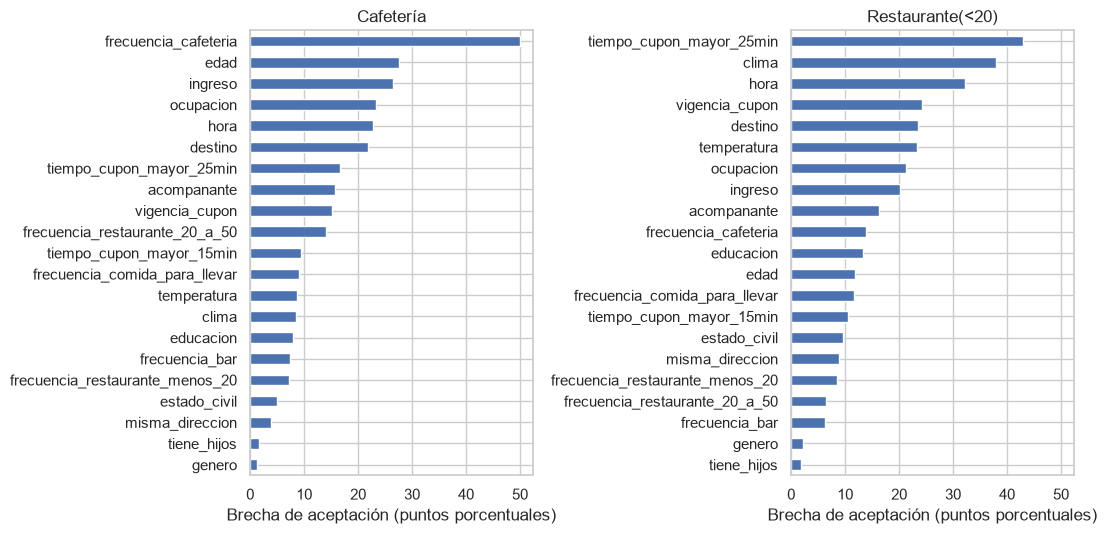

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharex=True)
for ax, nombre in zip(axes, ["Cafetería", "Restaurante(<20)"]):
    tabla_brecha[nombre].sort_values().plot.barh(ax=ax)
    ax.set_title(nombre)
    ax.set_xlabel("Brecha de aceptación (puntos porcentuales)")
plt.tight_layout()
plt.show()

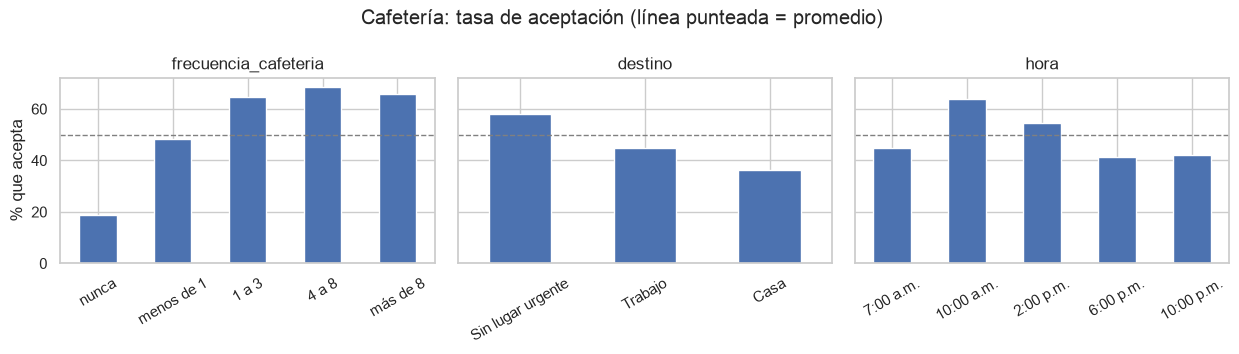

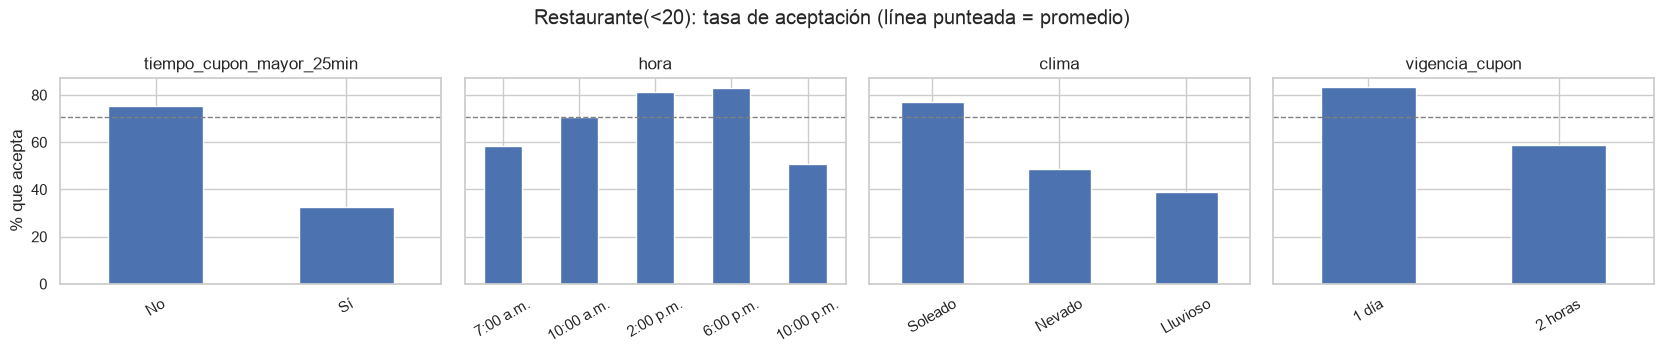

In [19]:
orden_frec = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]
orden_hora = ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."]
ordenes = {"frecuencia_cafeteria": orden_frec, "hora": orden_hora}

def graficar_tasas(datos, columnas, titulo):
    fig, axes = plt.subplots(1, len(columnas), figsize=(4.2 * len(columnas), 3.6), sharey=True)
    for ax, col in zip(axes, columnas):
        tasa = (datos["acepta_cupon"] == "Sí").groupby(datos[col]).mean() * 100
        if col in ordenes:
            tasa = tasa.reindex(ordenes[col])
        else:
            tasa = tasa.sort_values(ascending=False)
        tasa.plot.bar(ax=ax)
        ax.axhline((datos["acepta_cupon"] == "Sí").mean() * 100, color="gray", linestyle="--", linewidth=1)
        ax.set_title(col)
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=30)
    axes[0].set_ylabel("% que acepta")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

graficar_tasas(cafe, ["frecuencia_cafeteria", "destino", "hora"], "Cafetería: tasa de aceptación (línea punteada = promedio)")
graficar_tasas(rest, ["tiempo_cupon_mayor_25min", "hora", "clima", "vigencia_cupon"], "Restaurante(<20): tasa de aceptación (línea punteada = promedio)")

**Hallazgos.** Cada cupón se explica por cosas distintas. En **Cafetería** pesa el hábito del conductor, pues `frecuencia_cafeteria` tiene la mayor brecha (unos 50 puntos), con 19% de aceptación entre quienes nunca van a cafeterías y entre 65% y 69% entre quienes van varias veces al mes. En **Restaurante(<20)** pesa el contexto del viaje, ya que la distancia, el clima, la hora, la vigencia y el destino tienen brechas de 24 a 43 puntos, mientras que los hábitos del conductor tienen 14 o menos.

`genero`, `tiene_hijos` y `misma_direccion` tienen brechas menores a 10 puntos en ambos cupones. Las variables demográficas (`edad`, `ingreso`, `ocupacion`) muestran diferencias moderadas en Cafetería, aunque algunas categorías son pocas personas (el grupo "menor de 21" tiene 155 filas), y se retoman en el análisis de sesgo.

Algunos efectos no son monótonos, porque por hora o por ingreso la aceptación sube y baja. Un árbol lo capta, pero una regresión logística con categorías ordenadas solo ve una tendencia lineal, algo a recordar al leer sus coeficientes. Por ahora, ninguna variable se descarta.

### 1.9 Redundancia entre predictoras

Se revisa si algunas predictoras dicen casi lo mismo, porque eso vuelve inestables los coeficientes de la regresión logística. Se miran las parejas más evidentes de 1.6.

In [20]:
ambos = pd.concat([cafe, rest])

for a, b in [("destino", "hora"), ("clima", "temperatura"), ("destino", "misma_direccion")]:
    print(f"{b} según {a} (% por fila):")
    display(pd.crosstab(ambos[a], ambos[b], normalize="index").mul(100).round(0))

hora según destino (% por fila):


hora,10:00 a.m.,10:00 p.m.,2:00 p.m.,6:00 p.m.,7:00 a.m.
destino,,,,,
Casa,0.0,32.0,0.0,68.0,0.0
Sin lugar urgente,31.0,8.0,39.0,22.0,0.0
Trabajo,0.0,0.0,0.0,0.0,100.0


temperatura según clima (% por fila):


temperatura,30,55,80
clima,,,
Lluvioso,0.0,100.0,0.0
Nevado,100.0,0.0,0.0
Soleado,3.0,27.0,70.0


misma_direccion según destino (% por fila):


misma_direccion,No,Sí
destino,,
Casa,51.0,49.0
Sin lugar urgente,100.0,0.0
Trabajo,63.0,37.0


**Hallazgos y decisión.** Las superposiciones vienen del diseño de la encuesta. Ir al trabajo es siempre a las 7:00 a.m., ir a casa solo en la tarde o noche y "sin lugar urgente" a cualquier hora menos las 7:00 a.m., así que `hora` depende mucho de `destino`; además, la nieve es siempre a 30 °F y la lluvia a 55 °F, y sin lugar urgente `misma_direccion` es siempre "No".

Ninguna pareja es un duplicado y cada variable aporta algo propio (en Restaurante, `clima` y `temperatura` tienen brechas grandes), por lo que no se elimina ninguna por redundancia. La colinealidad que queda la controla la regularización, y los árboles no se ven afectados al predecir, aunque pueden repartir la importancia entre variables correlacionadas, algo a tener en cuenta en la Actividad 8.

En resumen, `direccion_opuesta` es redundante (ya eliminada), `destino`/`hora` y `clima`/`temperatura` se solapan en parte, y `genero`, `tiene_hijos`, `misma_direccion` y la constante `tiempo_cupon_mayor_5min` aportan poco.

### 1.10 Contraste con el archivo de prueba

Las predicciones finales se hacen sobre `Lab3_datos_Prueba`, así que se confirma que sea compatible con los datos de entrenamiento.

In [21]:
cols_prueba = [c for c in prueba.columns if c != "conductor"]  # 'conductor' es la clave creada en 1.5
print("Mismas columnas y en el mismo orden (sin la etiqueta):", cols_prueba == [c for c in df.columns if c != "acepta_cupon"])

nuevas = {c: set(prueba[c].dropna()) - set(df[c].dropna()) for c in cols_prueba}
print("Categorías de la prueba que no existen en entrenamiento:", {c: v for c, v in nuevas.items() if v})
print("Nulos en la prueba:", prueba[cols_prueba].isna().sum()[lambda s: s > 0].to_dict())
print("Filas duplicadas en la prueba:", prueba[cols_prueba].duplicated().sum())
print("Cupones en la prueba:", prueba["cupon"].value_counts().to_dict())

Mismas columnas y en el mismo orden (sin la etiqueta): True
Categorías de la prueba que no existen en entrenamiento: {}
Nulos en la prueba: {'vehiculo': 20}
Filas duplicadas en la prueba: 0
Cupones en la prueba: {'Cafetería': 10, 'Restaurante(<20)': 10}


**Hallazgos.** El archivo de prueba tiene las mismas columnas (menos la etiqueta), ninguna categoría nueva y ningún nulo aparte de `vehiculo`, que se elimina. Trae 10 filas de cada cupón y ningún duplicado, de modo que no requiere transformaciones especiales; se aplica el mismo pipeline y cada fila se predice con el modelo de su cupón.

### 1.11 Síntesis de la exploración

La tabla resume lo encontrado por dimensión de calidad y la decisión tomada, que se implementa en la Actividad 2.

| Dimensión | Hallazgo | Decisión |
|:---|:---|:---|
| **Completitud** | `vehiculo` tiene 99.15% de nulos y está vacía en la prueba | Se elimina |
| | `frecuencia_*` tiene entre 0.8% y 1.7% de nulos, por conductor | Imputar con la moda dentro del pipeline |
| **Unicidad** | 7 filas duplicadas exactas por cupón | Se eliminan antes de partir los datos |
| | 4 grupos (Cafetería) y 3 (Restaurante) con las mismas características y etiquetas distintas | Se conservan: es ruido real del problema |
| | Cada conductor aparece en varios escenarios (unos 565) | Riesgo de fuga por grupos: partición estratificada y, al final, verificación por grupos |
| **Consistencia** (mismo concepto escrito igual) | Sin variantes de escritura ni espacios sobrantes; `ingreso` se escribe distinto en el diccionario y en los datos; `edad` mezcla texto y números | Orden ordinal explícito, con el texto de los datos |
| **Validez** (dentro del dominio y coherente) | Todos los valores están en el dominio del diccionario; `temperatura` solo toma 30, 55 y 80 | Sin acción |
| | Relaciones entre columnas (clima y temperatura, destino y hora, distancias) sin violaciones | Sin acción |
| | `tiempo_cupon_mayor_5min` es constante | Se elimina |
| | 17 casos de "Hijo(s)" sin tener hijos y algunas combinaciones atípicas de edad con ocupación o educación | Se conservan, documentados |
| **Valores atípicos** | No hay variables continuas (solo `temperatura`, con tres valores fijos), así que no aplican los criterios Z ni IQR; hay categorías con menos de 30 filas (4 en Cafetería, 6 en Restaurante) | Se conservan; se controlan con regularización y `min_samples_leaf` |
| **Redundancia** | `direccion_opuesta` es el complemento exacto de `misma_direccion` | Se elimina |
| **Variable objetivo** | Cafetería 50/50; Restaurante 70.7% acepta y 29.3% rechaza | Partición y folds estratificados; F1 macro para elegir hiperparámetros |

De las 26 columnas quedan **21 predictoras** por cupón (se eliminan `vehiculo`, `cupon`, `direccion_opuesta` y `tiempo_cupon_mayor_5min`; `acepta_cupon` es el objetivo).

**Lo que se anticipa.** Cafetería depende sobre todo del hábito del conductor (`frecuencia_cafeteria`) y Restaurante(<20) del contexto del viaje. `genero`, `tiene_hijos` y `frecuencia_bar` casi no se relacionan con la aceptación. Son hipótesis que los modelos deben confirmar.

## <a id="actividad2"></a> Actividad 2 - Limpieza y preparación de los datos

Lo que no depende de los datos de entrenamiento, como quitar columnas inútiles y filas repetidas, se hace directamente antes de partir. Lo que sí aprende de ellos, como la moda para imputar y el escalado, va dentro de un `Pipeline`, para que se calcule solo con el entrenamiento de cada fold y no haya fuga de datos. Se trabaja siempre sobre copias.

### 2.1 Columnas que se eliminan

Se eliminan `vehiculo`, que tiene 99.15% de nulos y está vacía en la prueba, de modo que imputarla sería inventar datos; `cupon`, que es constante dentro de cada subconjunto; `tiempo_cupon_mayor_5min`, que vale "Sí" en el 100% de las filas; y `direccion_opuesta`, que es el complemento exacto de `misma_direccion` y causaría multicolinealidad perfecta.

In [22]:
columnas_eliminar = ["vehiculo", "cupon", "direccion_opuesta", "tiempo_cupon_mayor_5min"]

cafe_limpio = cafe.drop(columns=columnas_eliminar)
rest_limpio = rest.drop(columns=columnas_eliminar)

# Quedan las predictoras, la variable objetivo y la clave 'conductor' (que no se usa como variable)
predictoras_limpio = [c for c in cafe_limpio.columns if c not in ["acepta_cupon", "conductor"]]
print(f"Predictoras por cupón: {len(predictoras_limpio)}")

Predictoras por cupón: 21


### 2.2 Filas duplicadas

Las filas idénticas se eliminan **antes** de partir, para que una fila no quede en train y su copia en test, donde el modelo acertaría solo por haberla visto. Los escenarios iguales con respuestas distintas se conservan, porque no son copias sino ruido real.

In [23]:
n_antes = {"Cafetería": len(cafe_limpio), "Restaurante(<20)": len(rest_limpio)}
cafe_limpio = cafe_limpio.drop_duplicates()
rest_limpio = rest_limpio.drop_duplicates()
n_despues = {"Cafetería": len(cafe_limpio), "Restaurante(<20)": len(rest_limpio)}

resumen_duplicadas = pd.DataFrame({"antes": n_antes, "después": n_despues})
resumen_duplicadas["eliminadas"] = resumen_duplicadas["antes"] - resumen_duplicadas["después"]
resumen_duplicadas

print(f"Datos originales sin modificar: {datos_originales.shape}")

Datos originales sin modificar: (12664, 26)


Se eliminan 7 filas por subconjunto (menos del 0.3%). Quedan 3979 filas de Cafetería y 2769 de Restaurante(<20).

### 2.3 Partición en entrenamiento y prueba

Cada cupón se parte por separado, 75% para entrenamiento y 25% para prueba, de forma **estratificada** (conserva la proporción de "Sí" y "No") y con semilla fija para que sea reproducible. Se hace antes de ajustar cualquier paso que aprenda de los datos, y el conjunto de prueba se usa una sola vez, al final, para todos los modelos. La variable objetivo se codifica como Sí = 1 y No = 0, y la clave `conductor` se guarda aparte para la verificación por grupos.

In [24]:
def separar(datos):
    X = datos.drop(columns=["acepta_cupon", "conductor"])
    y = (datos["acepta_cupon"] == "Sí").astype(int)
    return train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

X_train_cafe, X_test_cafe, y_train_cafe, y_test_cafe = separar(cafe_limpio)
X_train_rest, X_test_rest, y_train_rest, y_test_rest = separar(rest_limpio)

# Clave de conductor de las filas de entrenamiento (para la verificación por grupos)
grupos_train_cafe = cafe_limpio.loc[X_train_cafe.index, "conductor"]
grupos_train_rest = rest_limpio.loc[X_train_rest.index, "conductor"]

for nombre, datos, Xtr, Xte, ytr, yte, gtr in [
    ("Cafetería", cafe_limpio, X_train_cafe, X_test_cafe, y_train_cafe, y_test_cafe, grupos_train_cafe),
    ("Restaurante(<20)", rest_limpio, X_train_rest, X_test_rest, y_train_rest, y_test_rest, grupos_train_rest),
]:
    visto = datos.loc[Xte.index, "conductor"].isin(gtr).mean()
    print(f"{nombre}: {len(Xtr)} filas de entrenamiento y {len(Xte)} de prueba")
    print(f"   % que acepta: entrenamiento {ytr.mean():.1%}, prueba {yte.mean():.1%} | casos 'No' en prueba: {(yte == 0).sum()}")
    print(f"   filas compartidas entre entrenamiento y prueba: {len(set(Xtr.index) & set(Xte.index))}")
    print(f"   filas de prueba cuyo conductor aparece en entrenamiento: {visto:.1%}")

Cafetería: 2984 filas de entrenamiento y 995 de prueba
   % que acepta: entrenamiento 49.8%, prueba 49.8% | casos 'No' en prueba: 499
   filas compartidas entre entrenamiento y prueba: 0
   filas de prueba cuyo conductor aparece en entrenamiento: 99.4%
Restaurante(<20): 2076 filas de entrenamiento y 693 de prueba
   % que acepta: entrenamiento 70.8%, prueba 70.7% | casos 'No' en prueba: 203
   filas compartidas entre entrenamiento y prueba: 0
   filas de prueba cuyo conductor aparece en entrenamiento: 98.3%


**Hallazgos.** Cafetería queda con 2984 filas de entrenamiento y 995 de prueba, y Restaurante(<20) con 2076 y 693. La proporción de clases se conserva, ninguna fila está en ambos conjuntos y en la prueba de Restaurante quedan 203 casos de "No", suficientes para medir el recall de la clase minoritaria. Se eligió 25% por ese motivo, dentro del rango habitual de 10% a 30%. Los nulos de `frecuencia_*` siguen en ambos conjuntos y se imputan dentro del pipeline.

### 2.4 Preprocesamiento

Se define un `ColumnTransformer` que aplica a cada grupo de columnas su propio tratamiento y que, dentro del `Pipeline` de cada modelo, se reajusta en cada fold solo con sus datos de entrenamiento. Las ordinales (`hora`, `edad`, `educacion`, `ingreso` y las cinco `frecuencia_*`) se imputan con la moda y se codifican como enteros con un orden explícito; las 6 binarias quedan en una columna 0/1 cada una; las nominales (`destino`, `acompanante`, `clima`, `estado_civil`, `ocupacion`) pasan a one-hot, porque no tienen orden; y `temperatura` es la única numérica.

Hay dos variantes. Para la **regresión logística** se estandarizan las ordinales y la temperatura, para que la regularización penalice por igual a todas, y en los nominales se elimina una categoría de referencia (`drop="first"`) para evitar la multicolinealidad con el intercepto. Para **árboles y Random Forest** no se escala, porque solo usan el orden de los valores.

In [25]:
frecuencias = [c for c in predictoras_limpio if c.startswith("frecuencia_")]
niveles_frecuencia = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]

# Orden de las ordinales, escrito con el texto exacto de los datos
orden = {
    "hora": ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."],
    "edad": ["menor de 21", "21", "26", "31", "36", "41", "46", "50 o más"],
    "educacion": ["Bachillerato incompleto", "Bachillerato completo", "Estudios universitarios sin título",
                  "Técnico/Tecnólogo", "Pregrado", "Posgrado (Maestría o Doctorado)"],
    "ingreso": ["Menos de $12.500", "$12.500 - $24.999", "$25.000 - $37.499", "$37.500 - $49.999",
                "$50.000 - $62.499", "$62.500 - $74.999", "$75.000 - $87.499", "$87.500 - $99.999",
                "$100.000 o más"],
}
for col in frecuencias:
    orden[col] = niveles_frecuencia

cols_ordinales = list(orden)
cols_binarias = ["genero", "tiene_hijos", "vigencia_cupon", "tiempo_cupon_mayor_15min",
                 "tiempo_cupon_mayor_25min", "misma_direccion"]
cols_nominales = ["destino", "acompanante", "clima", "estado_civil", "ocupacion"]
cols_numericas = ["temperatura"]

El orden de las ordinales se escribe a mano porque, si no, `OrdinalEncoder` las ordena alfabéticamente, y `$100.000 o más` quedaría como el ingreso más bajo, `10:00 p.m.` antes que `2:00 p.m.` y `menor de 21` como la edad más alta. Además, la lista fija los códigos aunque una categoría rara falte en un fold (`Bachillerato incompleto` tiene 18 filas en Restaurante).

In [26]:
def crear_preprocesador(para_logistica):
    ordinales = [
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("cod", OrdinalEncoder(categories=list(orden.values()),
                               handle_unknown="use_encoded_value", unknown_value=-1)),
    ]
    if para_logistica:
        ordinales.append(("esc", StandardScaler()))

    return ColumnTransformer([
        ("ord", Pipeline(ordinales), cols_ordinales),
        ("bin", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cols_binarias),
        ("nom", OneHotEncoder(drop="first" if para_logistica else None,
                              handle_unknown="ignore", sparse_output=False), cols_nominales),
        ("num", StandardScaler() if para_logistica else "passthrough", cols_numericas),
    ])

### 2.5 Verificación del preprocesamiento

Se ajusta cada preprocesador solo con entrenamiento y se aplica a entrenamiento y prueba, para comprobar que no quedan nulos y que las columnas coinciden.

In [27]:
assert sorted(cols_ordinales + cols_binarias + cols_nominales + cols_numericas) == sorted(predictoras_limpio)

filas = []
for cupon, Xtr, Xte in [("Cafetería", X_train_cafe, X_test_cafe),
                        ("Restaurante(<20)", X_train_rest, X_test_rest)]:
    for nombre, es_logistica in [("Regresión logística", True), ("Árbol / Random Forest", False)]:
        pre = crear_preprocesador(es_logistica).set_output(transform="pandas")
        Z_train = pre.fit_transform(Xtr)
        Z_test = pre.transform(Xte)
        filas.append({
            "cupón": cupon, "preprocesador": nombre, "columnas": Z_train.shape[1],
            "nulos train": int(Z_train.isna().sum().sum()), "nulos test": int(Z_test.isna().sum().sum()),
            "mismas columnas": list(Z_train.columns) == list(Z_test.columns),
        })
pd.DataFrame(filas)

,cupón,preprocesador,columnas,nulos train,nulos test,mismas columnas
0,Cafetería,Regresión logística,51,0,0,True
1,Cafetería,Árbol / Random Forest,56,0,0,True
2,Restaurante(<20),Regresión logística,51,0,0,True
3,Restaurante(<20),Árbol / Random Forest,56,0,0,True


In [28]:
# Moda con la que se imputan las frecuencias (aprendida solo con el entrenamiento de Cafetería)
imputador = crear_preprocesador(True).fit(X_train_cafe).named_transformers_["ord"].named_steps["imp"]
pd.Series(imputador.statistics_, index=cols_ordinales)[frecuencias].to_frame("moda")

,moda
frecuencia_bar,nunca
frecuencia_cafeteria,menos de 1
frecuencia_comida_para_llevar,1 a 3
frecuencia_restaurante_menos_20,1 a 3
frecuencia_restaurante_20_a_50,menos de 1


**Hallazgos.** Las 21 predictoras quedan cubiertas, sin nulos y con las mismas columnas en entrenamiento y prueba. Quedan 56 columnas para los árboles y 51 para la regresión logística, que elimina una categoría de referencia por variable nominal, y la moda de cada `frecuencia_*` se aprende solo con el entrenamiento. Con esto termina la preparación, y `X_train_*`, `X_test_*`, `y_train_*`, `y_test_*` y `crear_preprocesador` pasan a ser la entrada de las Actividades 3 a 5.

## <a id="actividad3"></a> Actividad 3 - Regresión logística

Se entrena un modelo por cupón, cada uno como un `Pipeline` con el preprocesador de la Actividad 2 y el clasificador, de modo que la imputación y el escalado se reajusten en cada fold. La búsqueda usa `GridSearchCV` con los mismos folds estratificados para todos los modelos y `f1_macro` como métrica, para que no parezca bueno un modelo que solo acierta la clase mayoritaria.

Se exploran el tipo de regularización, el solver y `C`. Para el tipo, en scikit-learn 1.8 el parámetro `penalty` quedó obsoleto y se elige con `l1_ratio` (0 es L2 y 1 es L1), con los mismos resultados; L2 encoge los coeficientes y L1 puede anular los de las variables menos útiles, y no se usa elastic net porque no se vio para clasificación. Con L2 se prueban los solvers `lbfgs`, `liblinear` y `newton-cg`, y con L1 solo `liblinear`, porque los otros no lo admiten, por lo que la grilla es una lista de dos diccionarios que evita combinaciones inválidas. Por último, `C` es el inverso de la fuerza de regularización y se prueba de 0.001 a 1000 en escala logarítmica, porque el mejor valor no se conoce.

No se usa `class_weight` porque este es el modelo sin balanceo, que la Actividad 6 compara con SMOTE, y el conjunto de prueba no se toca hasta evaluar todos los modelos.

In [29]:
pipeline_lr = Pipeline([
    ("pre", crear_preprocesador(para_logistica=True)),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

valores_C = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
param_grid_lr = [
    {"clf__l1_ratio": [0], "clf__solver": ["lbfgs", "liblinear", "newton-cg"], "clf__C": valores_C},  # L2
    {"clf__l1_ratio": [1], "clf__solver": ["liblinear"], "clf__C": valores_C},                          # L1
]

grid_lr_cafe = GridSearchCV(pipeline_lr, param_grid_lr, cv=skf, scoring="f1_macro", n_jobs=-1)
grid_lr_cafe.fit(X_train_cafe, y_train_cafe)

grid_lr_rest = GridSearchCV(pipeline_lr, param_grid_lr, cv=skf, scoring="f1_macro", n_jobs=-1)
grid_lr_rest.fit(X_train_rest, y_train_rest)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'clf__C': [0.001, 0.01, ...], 'clf__l1_ratio': [0], 'clf__solver': ['lbfgs', 'liblinear', ...]}, {'clf__C': [0.001, 0.01, ...], 'clf__l1_ratio': [1], 'clf__solver': ['liblinear']}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity

In [30]:
def resumir_busqueda(grid, X_train, y_train, nombre):
    mejor = grid.best_index_
    siempre_mayoritaria = np.full(len(y_train), y_train.mode()[0])
    print(nombre)
    print(f"   Mejores hiperparámetros: {grid.best_params_}")
    print(f"   F1 macro en validación cruzada: {grid.best_score_:.3f} ± {grid.cv_results_['std_test_score'][mejor]:.3f}")
    print(f"   F1 macro en entrenamiento:      {f1_score(y_train, grid.predict(X_train), average='macro'):.3f}")
    print(f"   F1 macro prediciendo siempre la clase mayoritaria: {f1_score(y_train, siempre_mayoritaria, average='macro'):.3f}")

def mejores_combinaciones(grid, n=5):
    r = pd.DataFrame(grid.cv_results_)
    columnas = [c for c in r.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "rank_test_score"]
    return r.sort_values("rank_test_score")[columnas].head(n).rename(columns=lambda c: c.replace("param_", "").replace("clf__", "")).round(3)

resumir_busqueda(grid_lr_cafe, X_train_cafe, y_train_cafe, "Cafetería")
resumir_busqueda(grid_lr_rest, X_train_rest, y_train_rest, "Restaurante(<20)")

Cafetería
   Mejores hiperparámetros: {'clf__C': 0.1, 'clf__l1_ratio': 0, 'clf__solver': 'liblinear'}
   F1 macro en validación cruzada: 0.709 ± 0.010
   F1 macro en entrenamiento:      0.722
   F1 macro prediciendo siempre la clase mayoritaria: 0.334
Restaurante(<20)
   Mejores hiperparámetros: {'clf__C': 100, 'clf__l1_ratio': 0, 'clf__solver': 'liblinear'}
   F1 macro en validación cruzada: 0.655 ± 0.019
   F1 macro en entrenamiento:      0.666
   F1 macro prediciendo siempre la clase mayoritaria: 0.414


In [31]:
print("Cafetería: mejores combinaciones")
display(mejores_combinaciones(grid_lr_cafe))
print("Restaurante(<20): mejores combinaciones")
display(mejores_combinaciones(grid_lr_rest))

Cafetería: mejores combinaciones


,C,l1_ratio,solver,mean_test_score,std_test_score,rank_test_score
7,0.10,0,liblinear,0.709,0.010,1
8,0.10,0,newton-cg,0.708,0.013,2
6,0.10,0,lbfgs,0.708,0.013,3
3,0.01,0,lbfgs,0.707,0.015,4
5,0.01,0,newton-cg,0.707,0.015,4


Restaurante(<20): mejores combinaciones


,C,l1_ratio,solver,mean_test_score,std_test_score,rank_test_score
27,1000.0,1,liblinear,0.655,0.019,1
19,1000.0,0,liblinear,0.655,0.019,1
16,100.0,0,liblinear,0.655,0.019,1
26,100.0,1,liblinear,0.655,0.019,1
20,1000.0,0,newton-cg,0.655,0.020,5


In [32]:
# Mejor F1 macro en validación cruzada para cada valor de C
def f1_por_C(grid):
    r = pd.DataFrame(grid.cv_results_)
    return r.groupby("param_clf__C")["mean_test_score"].max()

pd.DataFrame({"Cafetería": f1_por_C(grid_lr_cafe), "Restaurante(<20)": f1_por_C(grid_lr_rest)}).rename_axis("C").round(3)

,Cafetería,Restaurante(<20)
C,,
0.001,0.686,0.440
0.010,0.707,0.626
0.100,0.709,0.638
1.000,0.705,0.650
10.000,0.703,0.654
100.000,0.703,0.655
1000.000,0.703,0.655


**Análisis.** En **Cafetería** el mejor modelo usa L2 con `C = 0.1` y llega a un F1 macro de 0.709 en validación cruzada (± 0.010), muy por encima del 0.334 de un modelo que siempre responde lo mismo. Una regularización moderada ayuda, pues con `C = 0.001` baja a 0.686 y con valores grandes queda en 0.703, y L1 y L2 rinden casi igual, con solvers que coinciden.

En **Restaurante(<20)** el F1 macro es menor, 0.655 (± 0.019), frente a 0.414 de la referencia, y aquí regularizar no ayuda; el F1 sube con `C` hasta 10 y se queda plano (0.654 a 0.655), con diferencias mucho menores que la desviación entre folds, así que cualquier `C` grande sirve.

En ambos cupones el F1 de entrenamiento supera al de validación en apenas 0.01, es decir, no hay sobreajuste notable. Por qué Restaurante es más difícil se retoma en el análisis, y los coeficientes en la Actividad 8.

## <a id="actividad4"></a> Actividad 4 - Árboles de decisión

Se sigue el mismo esquema de la Actividad 3, pero con la variante del preprocesador sin escalado, porque los árboles solo usan el orden de los valores. La grilla cubre lo que pide el enunciado, con `max_depth` de 3, 5, 10 o sin límite, `min_samples_leaf` de 1, 5 o 20, y el criterio `gini` o `entropy`. Un árbol sin restricciones memoriza el entrenamiento, y los dos primeros hiperparámetros limitan su complejidad, mientras que el caso sin límite queda como referencia del sobreajuste. No se agregan `ccp_alpha`, `max_leaf_nodes` ni `splitter`, porque no se piden y la profundidad junto con la hoja mínima ya controlan el tamaño del árbol.

In [ ]:
pipeline_arbol = Pipeline([
    ("pre", crear_preprocesador(para_logistica=False)),
    ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])

param_grid_arbol = {
    "clf__max_depth": [3, 5, 10, None],
    "clf__min_samples_leaf": [1, 5, 20],
    "clf__criterion": ["gini", "entropy"],
}

grid_arbol_cafe = GridSearchCV(pipeline_arbol, param_grid_arbol, cv=skf, scoring="f1_macro", n_jobs=-1)
grid_arbol_cafe.fit(X_train_cafe, y_train_cafe)

grid_arbol_rest = GridSearchCV(pipeline_arbol, param_grid_arbol, cv=skf, scoring="f1_macro", n_jobs=-1)
grid_arbol_rest.fit(X_train_rest, y_train_rest)

In [ ]:
resumir_busqueda(grid_arbol_cafe, X_train_cafe, y_train_cafe, "Cafetería")
resumir_busqueda(grid_arbol_rest, X_train_rest, y_train_rest, "Restaurante(<20)")

for nombre, grid in [("Cafetería", grid_arbol_cafe), ("Restaurante(<20)", grid_arbol_rest)]:
    arbol = grid.best_estimator_.named_steps["clf"]
    print(f"{nombre}: el árbol elegido tiene profundidad {arbol.get_depth()} y {arbol.get_n_leaves()} hojas")

In [ ]:
print("Cafetería: mejores combinaciones")
display(mejores_combinaciones(grid_arbol_cafe))
print("Restaurante(<20): mejores combinaciones")
display(mejores_combinaciones(grid_arbol_rest))

In [ ]:
# Mejor F1 macro en validación cruzada para cada valor de un hiperparámetro
def mejor_por(grid, parametro):
    r = pd.DataFrame(grid.cv_results_)
    valores = r[f"param_clf__{parametro}"].map(str)  # None = sin límite
    return r.groupby(valores)["mean_test_score"].max()

por_profundidad = pd.DataFrame({
    "Cafetería": mejor_por(grid_arbol_cafe, "max_depth"),
    "Restaurante(<20)": mejor_por(grid_arbol_rest, "max_depth"),
}).reindex(["3", "5", "10", "None"]).rename_axis("max_depth")

por_criterio = pd.DataFrame({
    "Cafetería": mejor_por(grid_arbol_cafe, "criterion"),
    "Restaurante(<20)": mejor_por(grid_arbol_rest, "criterion"),
}).rename_axis("criterion")

display(por_profundidad.round(3))
display(por_criterio.round(3))

**Análisis.** En **Cafetería** el mejor árbol usa el criterio `entropy`, profundidad 5 y al menos 5 filas por hoja, con un F1 macro de 0.695 en validación cruzada (± 0.019), algo por debajo del 0.709 de la regresión logística. Con profundidad 3 el árbol queda corto (0.672), y desde 5 en adelante el resultado se estabiliza, de modo que más profundidad no ayuda. En **Restaurante(<20)** el patrón es el mismo, con `entropy`, profundidad 5 y al menos 20 filas por hoja, y un F1 macro de 0.648 (± 0.006) frente a 0.655 de la regresión logística.

El criterio casi no importa, ya que `entropy` supera a `gini` por menos de 0.01, que es menos de lo que varía entre folds. Tampoco hay un sobreajuste marcado, porque el F1 de entrenamiento supera al de validación en 0.02 a 0.03, e incluso con profundidad libre el árbol rinde casi igual que el podado (0.694 en Cafetería). Esto llama la atención, porque normalmente un árbol así memoriza y pierde en validación; aquí se relaciona con que los mismos conductores aparecen en train y en validación, de modo que memorizarlos no se castiga, un punto que se retoma al hablar de fuga por grupos. Las reglas del árbol se interpretan en la Actividad 8.